# Day 34 — More Than One Column
## Multiple linear regression

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

Yesterday: one input column. Today: as many as you like.

The maths is a small step — one number per column instead of one number in total.
**The hard part is reading the answer**, and that is where most of today goes.

| Part | What we do |
|---|---|
| **1** | Six flats, two facts each. A line becomes a plane |
| **2** | What each coefficient means — and the sign that flips |
| **3** | When two columns say the same thing |
| **4** | Is an extra column actually worth it? |
| **5** | Doing it for real: word columns, fair comparisons, the usual traps |

### Before you start

Run the cell below. Then **predict what each cell will print before you run it**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11

print("ready")

ready


---
# Part 1 · Adding a second column

## 1.1 · Six flats, two facts each

Yesterday you knew one thing about each flat. Now you know two.

In [2]:
flats = pd.DataFrame({
    "area":     [5., 7, 9, 11, 13, 9],    # hundreds of square feet
    "bedrooms": [1., 1, 2,  2,  3, 3],
    "rent":     [14., 16, 21, 27, 31, 23],  # Rs thousands per month
})
flats

,area,bedrooms,rent
0,5.0,1.0,14.0
1,7.0,1.0,16.0
2,9.0,2.0,21.0
3,11.0,2.0,27.0
4,13.0,3.0,31.0
5,9.0,3.0,23.0


### Look at flats 3 and 6

Both are **900 square feet**. One has two bedrooms and rents for ₹21,000; the other has
three and rents for ₹23,000.

A model that only knows the area **must predict the same number for both**, so it is
guaranteed to be wrong on at least one of them.

In [3]:
area_only = LinearRegression().fit(flats[["area"]], flats["rent"])

print("a model that only knows the area says:")
print("   flat 3 (900 sqft):", round(area_only.predict([[9]])[0], 2))
print("   flat 6 (900 sqft):", round(area_only.predict([[9]])[0], 2))
print()
print("they actually rent for 21 and 23.")

a model that only knows the area says:
   flat 3 (900 sqft): 22.0
   flat 6 (900 sqft): 22.0

they actually rent for 21 and 23.


## 1.2 · One number per column

Yesterday's model:

```
rent  =  slope × area  +  intercept
```

Today's model:

```
rent  =  w₁ × area  +  w₂ × bedrooms  +  intercept
```

**One number to multiply each column by, and still one number to add at the end.**

With ten columns you would have ten `w` numbers plus one intercept — eleven numbers, and
the model is complete.

*(Those `w` numbers go by several names: **coefficients**, **weights**, **parameters**,
**betas**. All the same thing. Textbooks use all four.)*

## 1.3 · Fit it

In [4]:
X = flats[["area", "bedrooms"]]      # a TABLE with two columns now
y = flats["rent"]

model = LinearRegression().fit(X, y)

print("coefficients:", model.coef_)
print("intercept   :", model.intercept_)

coefficients: [2. 1.]
intercept   : 2.0


### `rent = 2 × area + 1 × bedrooms + 2`

Two things to notice about `.coef_`:

1. It is a **list**, not a single number — one entry per column.
2. The order matches **the order of the columns in X**. `coef_[0]` goes with `area`
   because `area` came first.

Getting that order wrong is the most common bug in reading a multi-column model.

## 1.4 · Check it by hand

In [5]:
check = flats.copy()
check["2 × area"]   = 2 * check["area"]
check["1 × beds"]   = 1 * check["bedrooms"]
check["+ 2"]        = 2
check["model says"] = 2*check["area"] + 1*check["bedrooms"] + 2
check["error"]      = check["rent"] - check["model says"]
check

,area,bedrooms,rent,2 × area,1 × beds,+ 2,model says,error
0,5.0,1.0,14.0,10.0,1.0,2,13.0,1.0
1,7.0,1.0,16.0,14.0,1.0,2,17.0,-1.0
2,9.0,2.0,21.0,18.0,2.0,2,22.0,-1.0
3,11.0,2.0,27.0,22.0,2.0,2,26.0,1.0
4,13.0,3.0,31.0,26.0,3.0,2,31.0,0.0
5,9.0,3.0,23.0,18.0,3.0,2,23.0,0.0


In [6]:
print("errors add up to    :", check["error"].sum())
print("squared errors add to:", (check["error"] ** 2).sum())
print()
print("sklearn agrees:", np.allclose(model.predict(X), check["model says"]))

errors add up to    : 0.0
squared errors add to: 4.0

sklearn agrees: True


Errors add to **zero** and square to **4** — exactly the same two facts you checked
yesterday, just with one more column in the multiplication.

**A multi-column model is still only multiply-and-add.** You can verify every single
prediction with a calculator.

## 1.5 · Did the second column actually help?

In [7]:
def fit_and_report(columns):
    m = LinearRegression().fit(flats[columns], y)
    pred = m.predict(flats[columns])
    sse = ((y - pred) ** 2).sum()
    return m, r2_score(y, pred), sse

for cols in [["area"], ["bedrooms"], ["area", "bedrooms"]]:
    m, r2, sse = fit_and_report(cols)
    print(f"{str(cols):<24} R² {r2:.4f}    squared error {sse:>6.2f}")

['area']                 R² 0.9736    squared error   5.50
['bedrooms']             R² 0.6923    squared error  64.00
['area', 'bedrooms']     R² 0.9808    squared error   4.00


### Area was doing most of the work all along

Area alone already reaches **0.9736**. Adding bedrooms takes it to **0.9808**.

That looks like a small gain — but read it the other way: the squared error fell from
**5.5 to 4.0**, which is a **27% reduction**. Small is not nothing.

## 1.6 · So who works out the 2, the 1 and the 2?

Both routes from yesterday still work:

**The formula** still exists, but it is now a matrix calculation rather than something you
do on paper. `sklearn` runs it, and it is still exact.

**Gradient descent** works completely unchanged. Yesterday you nudged two numbers downhill;
now you nudge as many numbers as you have columns. The loop is identical.

Here it is, so you can see that nothing new happened:

In [8]:
def gradient_descent_many(X, y, rate=0.01, steps=40000):
    """Exactly yesterday's loop. The only change: w is now a LIST."""
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    n, k = X.shape

    w = np.zeros(k)          # one number per column
    b = 0.0

    for _ in range(steps):
        error = (X @ w + b) - y                 # line minus actual, as before
        w -= rate * (2/n) * (X.T @ error)       # one nudge per column
        b -= rate * (2/n) * error.sum()

    return w, b

w, b = gradient_descent_many(X, y)
print("gradient descent :", w.round(4), round(b, 4))
print("sklearn          :", model.coef_.round(4), round(model.intercept_, 4))

gradient descent : [2. 1.] 2.0
sklearn          : [2. 1.] 2.0


`X.T @ error` looks new, but it is only "do the same nudge for every column at once".
Nothing conceptual changed.

## 1.7 · A line becomes a flat sheet

With one input column the model was a **line**. With two it is a **plane** — a flat sheet
tilted in two directions at once.

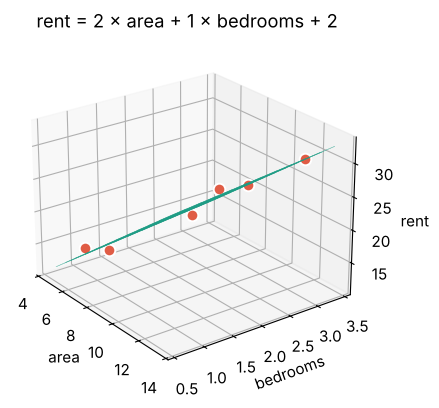

In [9]:
from mpl_toolkits.mplot3d import Axes3D   # noqa

fig = plt.figure(figsize=(6.5, 4.6))
ax = fig.add_subplot(projection="3d")

ga, gb = np.meshgrid(np.linspace(4.5, 13.5, 12), np.linspace(0.6, 3.4, 12))
ax.plot_surface(ga, gb, 2*ga + 1*gb + 2, alpha=0.4, color="#1F9E86",
                edgecolor="#1F9E86", linewidth=0.4)
ax.scatter(flats.area, flats.bedrooms, flats.rent, s=70, color="#E05C45",
           depthshade=False, edgecolor="white", lw=1.4)
ax.set_xlabel("area"); ax.set_ylabel("bedrooms"); ax.set_zlabel("rent")
ax.view_init(elev=24, azim=-37)
plt.title("rent = 2 × area + 1 × bedrooms + 2")
plt.show()

**This is the last time you can see the model.** With three input columns it becomes a
shape in four dimensions, which nobody can draw.

The arithmetic does not care. But from here on you have to reason about the *numbers*
rather than look at a picture — which is exactly why Parts 2 and 3 exist.

---
# Part 2 · What each number means

This is the part people get wrong.

## 2.1 · A bigger, more realistic dataset

In [10]:
rng = np.random.default_rng(3402)
N = 500

sqft     = rng.normal(980, 270, N).clip(380, 2100).round(0)
bedrooms = np.clip(np.round(sqft/430 + rng.normal(0, 0.42, N)), 1, 5)   # bigger flats have more
age      = rng.uniform(0, 30, N).round(0)
metro_km = rng.uniform(0.3, 9, N).round(2)

rent = (9000 + 23*sqft - 1500*bedrooms - 250*age - 950*metro_km
        + rng.normal(0, 3000, N)).clip(4000, None).round(0)

homes = pd.DataFrame({"sqft": sqft, "bedrooms": bedrooms, "age_years": age,
                      "metro_km": metro_km, "rent": rent})
homes.head()

,sqft,bedrooms,age_years,metro_km,rent
0,769.0,1.0,24.0,3.11,11851.0
1,949.0,3.0,1.0,3.51,24389.0
2,1097.0,3.0,12.0,2.08,22456.0
3,1096.0,3.0,19.0,2.21,21668.0
4,1320.0,3.0,23.0,0.32,26282.0


In [11]:
cols = ["sqft", "bedrooms", "age_years", "metro_km"]

X_train, X_hidden, y_train, y_hidden = train_test_split(
    homes[cols], homes["rent"], test_size=0.3, random_state=0)

big = LinearRegression().fit(X_train, y_train)

for name, value in zip(cols, big.coef_):
    print(f"   {name:<12} {value:>+12.2f}")
print(f"   {'intercept':<12} {big.intercept_:>+12.2f}")
print()
print(f"R² on rows it studied : {big.score(X_train, y_train):.4f}")
print(f"R² on rows it never saw: {big.score(X_hidden, y_hidden):.4f}")
print(f"average miss           : ₹{mean_absolute_error(y_hidden, big.predict(X_hidden)):,.0f} a month")

   sqft               +23.41
   bedrooms         -1449.71
   age_years         -224.25
   metro_km          -944.65
   intercept        +7882.88

R² on rows it studied : 0.8349
R² on rows it never saw: 0.8114
average miss           : ₹2,288 a month


### Read that in English

| column | coefficient | what it says |
|---|---|---|
| `sqft` | **+23.41** | one more square foot is worth ₹23 a month |
| `bedrooms` | **−1,449.71** | one more bedroom **costs** ₹1,450 a month |
| `age_years` | **−224.25** | each year of age knocks ₹224 off |
| `metro_km` | **−944.65** | each kilometre further out costs ₹945 |

**Read the bedrooms row again.** It is negative. More bedrooms, *less* rent.

That looks like a bug. It is not. Hold that thought — section 2.3 explains it, and it is
the most important idea of the day.

## 2.2 · First: what a coefficient actually promises

Every coefficient comes with a clause that people forget:

> **holding every other column constant**

"+₹23 per square foot" does **not** mean bigger flats cost ₹23 more per foot. It means:

In [12]:
flat_A = [[1000, 2, 8, 2.5]]
flat_B = [[1001, 2, 8, 2.5]]      # ONE extra square foot. Everything else identical.

print("flat A (1,000 sqft):  ₹", round(big.predict(flat_A)[0], 2))
print("flat B (1,001 sqft):  ₹", round(big.predict(flat_B)[0], 2))
print("difference         :  ₹", round(big.predict(flat_B)[0] - big.predict(flat_A)[0], 2))

flat A (1,000 sqft):  ₹ 24242.37
flat B (1,001 sqft):  ₹ 24265.78
difference         :  ₹ 23.41


**₹23.41 — the coefficient, exactly.**

A coefficient compares two rows that differ in **one** column and match on **every**
other. That is the whole definition, and almost every misreading comes from dropping the
second half.

It is also why a coefficient changes when you add or remove a column: you have changed
*what is being held still*.

## 2.3 · The sign that flips

Let us ask the bedrooms question two different ways.

In [13]:
alone = LinearRegression().fit(homes[["bedrooms"]], homes["rent"])
with_sqft = LinearRegression().fit(homes[["sqft", "bedrooms"]], homes["rent"])

print(f"bedrooms ALONE     : ₹{alone.coef_[0]:>+10,.1f} per bedroom")
print(f"bedrooms WITH sqft : ₹{with_sqft.coef_[1]:>+10,.1f} per bedroom")

bedrooms ALONE     : ₹  +4,682.9 per bedroom
bedrooms WITH sqft : ₹  -1,473.8 per bedroom


### Same column. Same 500 flats. Opposite signs.

Nothing was changed in the data. There is no bug. **Both numbers are correct.**

They are correct because they answer **two different questions**:

- *"Do flats with more bedrooms cost more?"* → **Yes**, because they are bigger.
- *"At the same area, does an extra bedroom add value?"* → **No**, because chopping a fixed
  area into more rooms makes them poky.

Here is the second question, asked without any model at all:

In [14]:
print("average rent by bedroom count — ALL 500 flats:")
print(homes.groupby("bedrooms").agg(flats=("rent", "size"),
                                    avg_sqft=("sqft", "mean"),
                                    avg_rent=("rent", "mean")).round(0).to_string())

average rent by bedroom count — ALL 500 flats:
          flats  avg_sqft  avg_rent
bedrooms                           
1.0          82     630.0   13717.0
2.0         235     908.0   18026.0
3.0         155    1159.0   22827.0
4.0          24    1495.0   28332.0
5.0           4    1702.0   30812.0


In [15]:
band = homes[(homes.sqft >= 850) & (homes.sqft <= 1150)]

print("now ONLY flats of 850–1,150 sqft — size held roughly still:")
print(band.groupby("bedrooms").agg(flats=("rent", "size"),
                                   avg_sqft=("sqft", "mean"),
                                   avg_rent=("rent", "mean")).round(0).to_string())

now ONLY flats of 850–1,150 sqft — size held roughly still:
          flats  avg_sqft  avg_rent
bedrooms                           
1.0           7     926.0   20529.0
2.0         133     984.0   19994.0
3.0          66    1036.0   19591.0
4.0           1    1145.0   22747.0


### There it is, with no regression involved

Across all 500 flats, average rent climbs with bedrooms: ₹13,717 → ₹18,026 → ₹22,827 →
₹28,332. Of course it does — the average size climbs too, from 630 to 1,495 sqft.

Among flats of a **similar size**, it goes the other way: ₹20,529 → ₹19,994 → ₹19,591.

*(The one-bedroom group has only 7 flats, so treat that bar loosely. The 2-vs-3 comparison
has 133 and 66 flats behind it.)*

**Multiple regression does this comparison automatically, for every column at once.** That
is what it is for.

### The rule to take away

> **A coefficient is not a property of its column.** It is a property of the column *and
> every other column in the model.*

So never report one on its own:

- ❌ "Bedrooms are worth −₹1,450."
- ✅ "Once area is accounted for, an extra bedroom is worth −₹1,450."

*(This pattern — a relationship that reverses when you look within subgroups — is called
**Simpson's paradox**. It is behind a great many wrong headlines, and multiple regression
is the standard tool for not falling for it.)*

## 2.4 · Predicting one flat

In [16]:
one_flat = {"sqft": 1100, "bedrooms": 3, "age_years": 8, "metro_km": 2.5}

running = big.intercept_
print(f"{'start (intercept)':<22} {big.intercept_:>+12.2f}")
for name, coefficient in zip(cols, big.coef_):
    piece = one_flat[name] * coefficient
    running += piece
    print(f"{name + ' × ' + str(one_flat[name]):<22} {piece:>+12.2f}")
print("-" * 36)
print(f"{'PREDICTED RENT':<22} {running:>12.2f}")
print()
print("sklearn:", round(big.predict([[1100, 3, 8, 2.5]])[0], 2))

start (intercept)          +7882.88
sqft × 1100               +25756.02
bedrooms × 3               -4349.12
age_years × 8              -1794.04
metro_km × 2.5             -2361.63
------------------------------------
PREDICTED RENT             25134.12

sklearn: 25134.12


**Five multiplications and one addition.** That is all a prediction ever is, however many
columns you have.

---
# Part 3 · When two columns say the same thing

## 3.1 · The extreme case

Somebody helpfully adds a `sqm` column — the area again, in square metres.

In [17]:
homes2 = homes.copy()
homes2["sqm"] = (homes2.sqft * 0.0929).round(2)

print("correlation between sqft and sqm:", round(homes2.sqft.corr(homes2.sqm), 6))
homes2[["sqft", "sqm"]].head()

correlation between sqft and sqm: 1.0


,sqft,sqm
0,769.0,71.44
1,949.0,88.16
2,1097.0,101.91
3,1096.0,101.82
4,1320.0,122.63


In [18]:
both_cols = ["sqft", "sqm", "bedrooms", "age_years", "metro_km"]

print(f"{'split':<8}{'coef on sqft':>16}{'coef on sqm':>16}{'combined /sqft':>18}{'hidden R²':>12}")
print("-" * 70)
for seed in [0, 1, 2, 3]:
    a, b, c, d = train_test_split(homes2[both_cols], homes2.rent,
                                  test_size=0.3, random_state=seed)
    m = LinearRegression().fit(a, c)
    combined = m.coef_[0] + m.coef_[1]*0.0929      # sqm converted back to per-sqft
    print(f"{seed:<8}{m.coef_[0]:>+16.2f}{m.coef_[1]:>+16.2f}"
          f"{combined:>+18.2f}{m.score(b, d):>12.4f}")

split       coef on sqft     coef on sqm    combined /sqft   hidden R²
----------------------------------------------------------------------
0               +1434.81       -15192.61            +23.42      0.8113
1                 +89.30         -711.58            +23.19      0.7939
2                -882.88        +9753.58            +23.22      0.8707
3               +2090.27       -22256.91            +22.60      0.8512


### Look at what moved, and what did not

The two coefficients **swing wildly** — from +1,435 to −883 on `sqft`, and from −22,257 to
+9,754 on `sqm`. Change the split and you get a completely different story.

But the last two columns barely move:

- their **combined effect** is about **+₹23 per square foot**, every single time
- the **hidden R²** is unaffected

### Why

The model is asked: "how much credit goes to `sqft` and how much to `sqm`?" Since they are
the same column, **any split of the credit gives identical predictions**. +1,435 and
−15,193 work exactly as well as −883 and +9,754. The model picks one arbitrarily, and
picks differently each time.

**The model is fine. The explanation is ruined.**

In [19]:
without = LinearRegression().fit(X_train, y_train)
a, b, c, d = train_test_split(homes2[both_cols], homes2.rent, test_size=0.3, random_state=0)
with_sqm = LinearRegression().fit(a, c)

print(f"{'':<24}{'without sqm':>14}{'with sqm':>14}")
print("-" * 52)
print(f"{'R² on hidden rows':<24}{without.score(X_hidden, y_hidden):>14.4f}{with_sqm.score(b, d):>14.4f}")
print(f"{'average miss':<24}{mean_absolute_error(y_hidden, without.predict(X_hidden)):>14,.0f}"
      f"{mean_absolute_error(d, with_sqm.predict(b)):>14,.0f}")
print(f"{'coefficient on sqft':<24}{without.coef_[0]:>14.2f}{with_sqm.coef_[0]:>14.2f}")

                           without sqm      with sqm
----------------------------------------------------
R² on hidden rows               0.8114        0.8113
average miss                     2,288         2,288
coefficient on sqft              23.41       1434.81


### This has a name: multicollinearity

The plain version: **two columns are telling the model the same thing, so it cannot decide
which one to thank.**

Be precise about the harm:

| | damaged? |
|---|---|
| predictions | **no** |
| R² | **no** |
| the coefficients | **ruined** |
| your ability to explain the model | **ruined** |

If you only want predictions, it barely matters. If you want to tell somebody what drives
rent, it matters completely — because your headline number is now whatever the split
happened to pick.

## 3.2 · How to spot it

In [20]:
homes[cols].corr().round(2)

,sqft,bedrooms,age_years,metro_km
sqft,1.00,0.79,0.06,0.03
bedrooms,0.79,1.00,0.04,0.04
age_years,0.06,0.04,1.00,0.03
metro_km,0.03,0.04,0.03,1.00


### `sqft` and `bedrooms` correlate at 0.79. Should we drop one?

**No.** And this is the part most tutorials get wrong.

You will read a rule online: "drop a column if correlation is above 0.8". Look at what
that rule would have cost us here — dropping `bedrooms` would have thrown away the most
interesting finding of the day, the fact that an extra bedroom at a fixed area is worth
**−₹1,450**.

**The real question is not "do these two columns move together?" but "do these two columns
MEAN the same thing?"**

- `sqft` and `sqm` are the same measurement in different units → **drop one**
- `sqft` and `bedrooms` are genuinely different facts that happen to correlate → **keep both**

Correlation is a flag to investigate, not a rule to obey.

### The second way to spot it

Refit on a few different splits. If a coefficient swings wildly while the score stays put,
two columns are competing for the same credit — which is exactly what you saw in 3.1.

---
# Part 4 · Is the extra column worth it?

## 4.1 · R² can never go down

Watch what happens when we add columns of **pure random numbers**.

In [21]:
def adjusted_r2(r2, n_rows, n_cols):
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_cols - 1)

junk_rng = np.random.default_rng(777)
train = X_train.copy()
hidden = X_hidden.copy()
use = list(cols)

print(f"{'junk columns':>14}{'R² studied':>13}{'adjusted R²':>14}{'R² hidden':>12}")
print("-" * 53)
for batch in range(0, 7):
    if batch:
        for q in range(5):
            name = f"junk{batch}_{q}"
            train[name]  = junk_rng.normal(0, 1, len(train))
            hidden[name] = junk_rng.normal(0, 1, len(hidden))
            use.append(name)
    m = LinearRegression().fit(train[use], y_train)
    tr = m.score(train[use], y_train)
    print(f"{batch*5:>14}{tr:>13.4f}"
          f"{adjusted_r2(tr, len(train), len(use)):>14.4f}"
          f"{m.score(hidden[use], y_hidden):>12.4f}")

  junk columns   R² studied   adjusted R²   R² hidden
-----------------------------------------------------
             0       0.8349        0.8330      0.8114
             5       0.8374        0.8331      0.8064
            10       0.8418        0.8352      0.8011
            15       0.8437        0.8347      0.7949
            20       0.8456        0.8342      0.7880
            25       0.8477        0.8338      0.7792
            30       0.8496        0.8334      0.7731


### Three columns of numbers, three different stories

**Plain R² rose every single time**, from 0.8349 to 0.8496. Thirty columns of random noise
made the model look *better*.

**Why can it never fall?** Because the model could always set a useless column's
coefficient to exactly zero and be precisely as good as before. So the best it can do
never gets worse — it can only find some tiny accidental pattern and do slightly better.

**Adjusted R² barely flinched**: 0.8330 → 0.8334. It subtracts a penalty for each column,
which does stop the automatic climb — but with 350 rows the penalty is tiny.

**The hidden score fell steadily**: 0.8114 → 0.7731. That is the truth.

### So be honest about adjusted R²

Most textbooks present it as the answer to this problem. On this data it is **a weak
guard, not a safe one** — it stayed flat while the honest score dropped by 0.04.

**Hide rows and measure there.** That is the only one of the three that answers the
question you actually asked.

## 4.2 · So add columns one at a time

In [22]:
previous = None
for k in range(1, 5):
    use_now = cols[:k]
    a, b, c, d = train_test_split(homes[use_now], homes.rent, test_size=0.3, random_state=0)
    m = LinearRegression().fit(a, c)
    hidden_r2 = m.score(b, d)
    miss = mean_absolute_error(d, m.predict(b))
    change = "" if previous is None else f"  ({hidden_r2 - previous:+.4f})"
    print(f"{str(use_now):<48} hidden R² {hidden_r2:.4f}{change}   miss ₹{miss:,.0f}")
    previous = hidden_r2

['sqft']                                         hidden R² 0.5935   miss ₹3,403
['sqft', 'bedrooms']                             hidden R² 0.6154  (+0.0218)   miss ₹3,324
['sqft', 'bedrooms', 'age_years']                hidden R² 0.7168  (+0.1014)   miss ₹2,844
['sqft', 'bedrooms', 'age_years', 'metro_km']    hidden R² 0.8114  (+0.0945)   miss ₹2,288


### All four earned their place — but very unevenly

- `bedrooms` bought **+0.022**
- `age_years` bought **+0.101**
- `metro_km` bought **+0.095**

Add them all at once and you would see the score climb from 0.59 to 0.81 and conclude they
were all good. One at a time tells you that age was worth **five times** what bedrooms was.

And the average miss fell from **₹3,403 to ₹2,288** — about ₹1,100 better per flat. That
is the number to quote to somebody who does not know what R² is.

---
# Part 5 · Doing it for real

## 5.1 · A word column

We go back and collect one more fact about each flat: is it furnished, semi-furnished, or
unfurnished?

In [23]:
furn_rng = np.random.default_rng(3403)
furnishing = furn_rng.choice(["unfurnished", "semi", "full"], N, p=[.45, .35, .20])
bump = np.where(furnishing == "full", 4200, np.where(furnishing == "semi", 1900, 0))

homes3 = homes.copy()
homes3["furnishing"] = furnishing
homes3["rent"] = (homes.rent + bump + furn_rng.normal(0, 400, N)).round(0)

homes3.groupby("furnishing").rent.agg(["size", "mean"]).round(0)

,size,mean
furnishing,,
full,105,23045.0
semi,186,22047.0
unfurnished,209,19008.0


A model cannot multiply the word "semi" by anything — exactly the problem from Day 31. So
we **one-hot encode** it.

In [24]:
encoded = pd.get_dummies(
    homes3[["sqft", "bedrooms", "age_years", "metro_km", "furnishing"]],
    columns=["furnishing"], drop_first=True).astype(float)

print("columns now:", list(encoded.columns))
encoded.head()

columns now: ['sqft', 'bedrooms', 'age_years', 'metro_km', 'furnishing_semi', 'furnishing_unfurnished']


,sqft,bedrooms,age_years,metro_km,furnishing_semi,furnishing_unfurnished
0,769.0,1.0,24.0,3.11,0.0,0.0
1,949.0,3.0,1.0,3.51,0.0,0.0
2,1097.0,3.0,12.0,2.08,0.0,1.0
3,1096.0,3.0,19.0,2.21,1.0,0.0
4,1320.0,3.0,23.0,0.32,0.0,0.0


### Three categories became TWO columns, not three

`drop_first=True` deliberately left one category out. **That is not an accident, and it is
not information thrown away.**

| furnishing | furnishing_semi | furnishing_unfurnished |
|---|---|---|
| **full** | 0 | 0 |
| semi | 1 | 0 |
| unfurnished | 0 | 1 |

"Full" is identified by both columns being zero. Keeping a third column would mean the
three always add to 1 for every row — **the same information twice**, which is exactly the
`sqft`/`sqm` problem from Part 3.

In [25]:
a, b, c, d = train_test_split(encoded, homes3.rent, test_size=0.3, random_state=0)
furnished_model = LinearRegression().fit(a, c)

for name, value in zip(encoded.columns, furnished_model.coef_):
    print(f"   {name:<24} {value:>+12.2f}")
print(f"   {'intercept':<24} {furnished_model.intercept_:>+12.2f}")

   sqft                           +23.23
   bedrooms                     -1332.93
   age_years                     -221.25
   metro_km                      -941.79
   furnishing_semi              -2389.50
   furnishing_unfurnished       -4554.65
   intercept                   +12100.44


### Reading a one-hot coefficient

`furnishing_unfurnished = −4,554.65` means:

> An unfurnished flat rents for about ₹4,555 less **than a fully furnished flat of the same
> size, age and distance**.

Every furnishing coefficient is measured against **the category that was dropped**. The
dropped one does not vanish — it becomes the **zero point**.

Change which category you drop and all these numbers change. **Every prediction stays
identical.**

## 5.2 · Did the furnishing column earn its place?

In [26]:
plain_cols = ["sqft", "bedrooms", "age_years", "metro_km"]
a0, b0, c0, d0 = train_test_split(encoded[plain_cols], homes3.rent,
                                  test_size=0.3, random_state=0)
no_furnishing = LinearRegression().fit(a0, c0)

print(f"without furnishing : R² {no_furnishing.score(b0, d0):.4f}"
      f"   miss ₹{mean_absolute_error(d0, no_furnishing.predict(b0)):,.0f}")
print(f"with furnishing    : R² {furnished_model.score(b, d):.4f}"
      f"   miss ₹{mean_absolute_error(d, furnished_model.predict(b)):,.0f}")

without furnishing : R² 0.7716   miss ₹2,636
with furnishing    : R² 0.8298   miss ₹2,278


**+0.058 on the hidden rows**, and the average miss fell by about **₹360 a flat**.

Always have both numbers ready. R² convinces a statistician; ₹360 a flat convinces
everybody else.

## 5.3 · Which column matters most?

Tempting answer: the one with the biggest coefficient. **That answer is wrong.**

In [27]:
scaler = StandardScaler().fit(a)
scaled_model = LinearRegression().fit(scaler.transform(a), c)

comparison = pd.DataFrame({
    "column": encoded.columns,
    "raw coefficient": furnished_model.coef_.round(2),
    "scaled coefficient": scaled_model.coef_.round(0),
})
comparison["size (scaled)"] = comparison["scaled coefficient"].abs()
comparison.sort_values("size (scaled)", ascending=False).drop(columns="size (scaled)")

,column,raw coefficient,scaled coefficient
0,sqft,23.23,6577.0
3,metro_km,-941.79,-2416.0
5,furnishing_unfurnished,-4554.65,-2229.0
2,age_years,-221.25,-1965.0
4,furnishing_semi,-2389.50,-1171.0
1,bedrooms,-1332.93,-1085.0


### Raw, `sqft` looks like the smallest effect in the model

+23.23, against −4,554 for `furnishing_unfurnished`. Two hundred times smaller!

But of course it is — **one square foot is a tiny amount of area.** The coefficient is per
*unit*, and the units are wildly different: square feet run to 2,100, while
`furnishing_unfurnished` is only ever 0 or 1.

**After scaling, `sqft` is the biggest effect by a factor of nearly three.** Scaling puts
every column in the same units ("one standard deviation"), which is the only way the
numbers can be compared.

Remember from Day 32: scaling does **not** change a linear model's predictions at all. It
changes whether its coefficients can be compared with each other.

## 5.4 · Check the errors

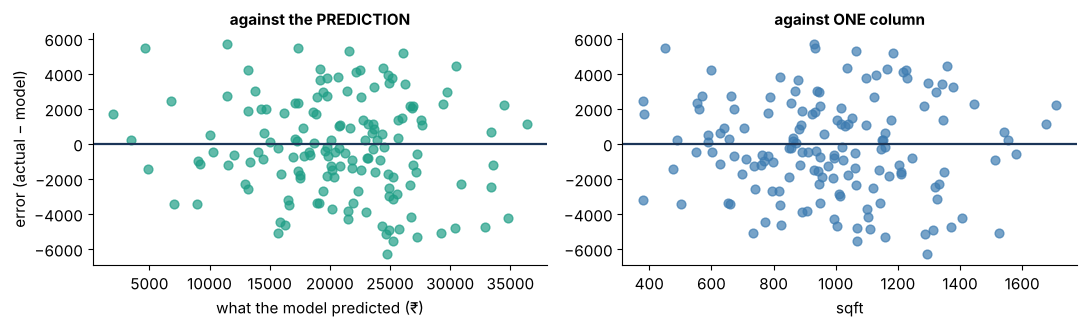

In [28]:
residuals = d - furnished_model.predict(b)
predicted = furnished_model.predict(b)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].axhline(0, color="#1B3558", lw=1.6)
axes[0].scatter(predicted, residuals, s=40, color="#1F9E86", alpha=0.7)
axes[0].set_xlabel("what the model predicted (₹)")
axes[0].set_ylabel("error (actual − model)")
axes[0].set_title("against the PREDICTION", fontweight="bold", fontsize=11)

axes[1].axhline(0, color="#1B3558", lw=1.6)
axes[1].scatter(b.sqft, residuals, s=40, color="#3E7CB1", alpha=0.7)
axes[1].set_xlabel("sqft")
axes[1].set_title("against ONE column", fontweight="bold", fontsize=11)

plt.tight_layout(); plt.show()

In [29]:
print("average error by slice of predicted rent:")
for lo, hi in [(0, 20000), (20000, 26000), (26000, 32000), (32000, 99000)]:
    k = (predicted >= lo) & (predicted < hi)
    if k.sum():
        print(f"   predicted ₹{lo:,}–{hi:,}: {residuals[k].mean():>+9.1f}   ({k.sum()} flats)")

average error by slice of predicted rent:
   predicted ₹0–20,000:     +97.5   (64 flats)
   predicted ₹20,000–26,000:    -494.2   (60 flats)
   predicted ₹26,000–32,000:     -12.7   (19 flats)
   predicted ₹32,000–99,000:   -1231.3   (7 flats)


### With many columns, plot the errors against the PREDICTION

With one column you plotted errors against that column. With six you would need six
charts — so instead plot them against the model's own output. **One chart that covers the
whole model at once.**

Both are useful:

- **errors vs prediction** catches the model being wrong at one end of its range
- **errors vs one column** catches *that column* being the wrong shape

Here every slice sits within a few hundred rupees of zero, against an average miss of
₹2,278. No pattern. The model fits.

## 5.5 · ⚠️ Four columns, four ways to walk off the edge

In [30]:
for name in cols:
    print(f"   {name:<12} runs from {homes[name].min():>8.1f} to {homes[name].max():>8.1f}")

   sqft         runs from    380.0 to   1879.0
   bedrooms     runs from      1.0 to      5.0
   age_years    runs from      0.0 to     30.0
   metro_km     runs from      0.3 to      9.0


Yesterday you checked one interval. Now you must check four. **And that is still not
enough.**

In [31]:
# every value below is inside its own column's range...
impossible = [[400, 5, 2, 1.0]]     # a 400 sqft flat with FIVE bedrooms

lo, hi = homes.sqft.min(), homes.sqft.max()
print(f"sqft 400   inside {lo:.0f}–{hi:.0f} ?", lo <= 400 <= hi)
print(f"beds 5     inside {homes.bedrooms.min():.0f}–{homes.bedrooms.max():.0f}       ?",
      homes.bedrooms.min() <= 5 <= homes.bedrooms.max())
print()
print("the model confidently says: ₹", round(big.predict(impossible)[0], 2))
print()
tiny = homes[(homes.sqft < 600)]
print("but how many flats under 600 sqft had 4 or more bedrooms?",
      (tiny.bedrooms >= 4).sum(), "out of", len(tiny))

sqft 400   inside 380–1879 ? True
beds 5     inside 1–5       ? True

the model confidently says: ₹ 8607.02

but how many flats under 600 sqft had 4 or more bedrooms? 0 out of 45


### Every value is in range. The *combination* never happened.

A 400 square foot flat with five bedrooms does not exist in the data — and probably not in
the city. The model has never seen anything like it, so its answer is invention, however
reasonable each individual number looks.

**With one column you check an interval. With many, you must also ask whether that
combination ever occurred.**

## 5.6 · The five steps, updated

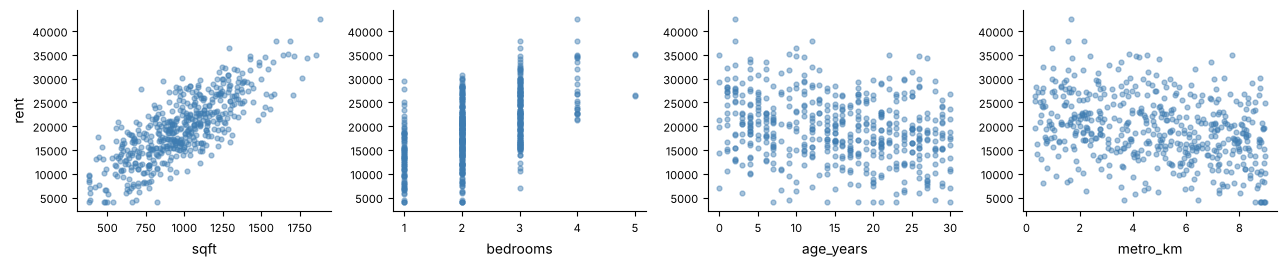

correlations between the INPUT columns — looking for two that mean the same thing:
           sqft  bedrooms  age_years  metro_km
sqft       1.00      0.79       0.06      0.03
bedrooms   0.79      1.00       0.04      0.04
age_years  0.06      0.04       1.00      0.03
metro_km   0.03      0.04       0.03      1.00


In [32]:
#  1 · LOOK — one scatter per column, PLUS the correlations between inputs
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, name in zip(axes, cols):
    ax.scatter(homes[name], homes.rent, s=12, color="#3E7CB1", alpha=0.45)
    ax.set_xlabel(name, fontsize=10)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("rent", fontsize=10)
plt.tight_layout(); plt.show()

print("correlations between the INPUT columns — looking for two that mean the same thing:")
print(homes[cols].corr().round(2).to_string())

In [33]:
#  2 · SPLIT
a, b, c, d = train_test_split(encoded, homes3.rent, test_size=0.3, random_state=0)

#  3 · ENCODE  (already done above with get_dummies; scale only to COMPARE)
#  4 · FIT & READ
m = LinearRegression().fit(a, c)
print("4 · READ")
for name, value in zip(encoded.columns, m.coef_):
    print(f"      {name:<24} {value:>+12.2f}")

#  5 · CHECK
print()
print("5 · CHECK")
print(f"      R² on hidden rows : {m.score(b, d):.4f}")
print(f"      average miss      : ₹{mean_absolute_error(d, m.predict(b)):,.0f} a month")

4 · READ
      sqft                           +23.23
      bedrooms                     -1332.93
      age_years                     -221.25
      metro_km                      -941.79
      furnishing_semi              -2389.50
      furnishing_unfurnished       -4554.65

5 · CHECK
      R² on hidden rows : 0.8298
      average miss      : ₹2,278 a month


## 5.7 · Five mistakes everybody makes once

| # | The mistake | What you will see | The fix |
|---|---|---|---|
| 1 | Reading a coefficient on its own | "Bedrooms are worth −₹1,450" | Always say what else is in the model |
| 2 | Comparing raw coefficient sizes | "sqft barely matters, it is only 23" | Scale the columns first |
| 3 | Judging a column by plain R² | Every column looks like it helped | Hide rows and measure there |
| 4 | Keeping two columns that mean the same | Coefficients that swing between splits | Drop one, or combine them |
| 5 | Predicting an impossible combination | A confident number for a 400 sqft 5BHK | Check the combination, not just each range |

**Number 1 is the one that ends up in reports.** A coefficient without its context is not
a finding — it is a number that happens to be true of one particular model.

---

# What to remember

| | |
|---|---|
| **One number per column** | `answer = w₁x₁ + w₂x₂ + … + intercept`. Nothing else about yesterday changed |
| **Coefficients hold the rest still** | "+₹23 per sqft" compares two flats identical in every other column. That clause is not optional |
| **A sign can legitimately flip** | Bedrooms: +₹4,683 alone, −₹1,474 beside area. Both correct — they answer different questions |
| **Overlapping columns ruin the story** | `sqft` and `sqm` left predictions untouched and made the coefficients meaningless |
| **R² always rises** | Thirty junk columns raised it every time. Adjusted R² barely flinched. Only the hidden rows told the truth |
| **Scale before you compare** | Raw, `sqft` looked like the smallest effect. Scaled, it was three times the next one |

---

### Tonight

19 practice questions. Part D hands you a hospital model that appears to blame nurses for
patient deaths, and asks you to find the column that explains it.

### Next

**Day 35 — logistic regression.** The same machinery, but the answer is yes or no instead
of a number.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*